# Actividad 4 · Selección, comparación y justificación de modelos preentrenados
**Caso de uso:** predicción de churn de clientes de telecomunicaciones (*Sierra Móvil*, Fase I) con el dataset

**Telco Customer Churn** (IBM / Kaggle, 7,043 clientes).

**Rama de IA:** datos tabulares (clasificación binaria) ·

**Entorno:** Google Colab con GPU T4 ·

**Ecosistema:** Hugging Face (Models).

**Pregunta de decisión:**

¿qué modelo preentrenado de Hugging Face conviene para generar cada mes la lista del 15 % de clientes con mayor riesgo de baja, equilibrando precisión, latencia y costo?

**Modelos comparados (al menos tres, todos de Hugging Face):**

| # | Modelo | Enfoque |
|---|---|---|
| 1 | `Prior-Labs/tabpfn_3` (TabPFN-3) | Modelo fundacional tabular, **sin entrenamiento** (aprendizaje en contexto) |
| 2 | `google/bert_uncased_L-4_H-256_A-4` (BERT-mini) | Encoder de texto pequeño + ajuste fino mínimo |
| 3 | `distilbert-base-uncased` (DistilBERT) | Encoder de texto mediano + ajuste fino mínimo |
| 4 | `roberta-base` (RoBERTa-base) | Encoder de texto grande + ajuste fino mínimo |

Modelos no preentrenados se incluyen regresión logística, HistGradientBoosting, para conocer si lo complejo de un modelo preentrenado se justifica.

## 1. Configuración de GPU
`Entorno de ejecución → Cambiar tipo de entorno de ejecución → GPU T4`. Si `nvidia-smi` muestra información de NVIDIA, la GPU está activa.

In [1]:
!nvidia-smi
import torch
print("CUDA disponible:", torch.cuda.is_available())

Mon Oct 12 02:56:56 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   46C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## 2. Instalación de dependencias
Si aparece un error de importación después de instalar, usa

**Entorno de ejecución - Reiniciar sesión**

y vuelve a ejecutar desde esta celda.

In [2]:
!pip install -q transformers datasets evaluate huggingface_hub tabpfn scikit-learn pandas matplotlib
import numpy, pandas, sklearn, transformers, datasets, torch
print("numpy", numpy.__version__, "| pandas", pandas.__version__, "| scikit-learn", sklearn.__version__)
print("transformers", transformers.__version__, "| datasets", datasets.__version__, "| torch", torch.__version__)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 3.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 849.3/849.3 kB 43.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 69.4/69.4 kB 7.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 595.9/595.9 kB 30.5 MB/s eta 0:00:00
numpy 2.1.3 | pandas 2.2.3 | scikit-learn 1.6.1
transformers 5.18.0 | datasets 4.8.5 | torch 2.11.0+cu130


## 3. Autenticación en Hugging Face Hub
1. Se Creó un token tipo **Read** en *huggingface.co → Settings → Access Tokens*.
2. En Colab: 🔑 → **Secrets** → nombre `HF_TOKEN` → activar acceso al cuaderno.
3. **TabPFN-3 es un modelo con acceso restringido (gated):** abre `https://huggingface.co/Prior-Labs/tabpfn_3` con tu cuenta y acepta la licencia. Su licencia (`tabpfn-3-license-v1.0`) es permisiva para investigación y evaluación interna limitada; **para uso en producción requiere licencia comercial**. Esto es un criterio de selección y se discute en el reporte.


In [3]:
import os
try:
    from google.colab import userdata
    os.environ["HF_TOKEN"] = userdata.get("HF_TOKEN")
    print("HF_TOKEN cargado desde Secrets de Colab.")
except Exception as e:
    print("No se encontró el Secret HF_TOKEN (", type(e).__name__, ") -> login interactivo")
    from huggingface_hub import login
    login()

from huggingface_hub import whoami
try:
    print("Sesión en Hugging Face como:", whoami()["name"])
except Exception as e:
    print("No se pudo validar la sesión:", e)

HF_TOKEN cargado desde Secrets de Colab.
Sesión en Hugging Face como: emilioalcala01


## 4. Datos: origen, preparación y partición
**Origen:** *Telco Customer Churn* (IBM Sample Data Sets), publicado en Kaggle (`blastchar/telco-customer-churn`). 7,043 filas × 21 columnas; una fila = un cliente.

**Cómo obtener el archivo** (en este orden):

(a) si ya está en `data/raw/`, se usa;

(b) si defines `REPO_URL`, se clona tu repositorio de GitHub;

(c) si no, Colab te pedirá subir `WA_Fn-UseC_-Telco-Customer-Churn.csv`.

**Preparación (script reproducible `src/prepare_dataset.py`):**

`TotalCharges` a numérico (11 vacíos con `tenure = 0` → 0),

`Churn` a 0/1,

partición **estratificada 70/15/15 (train/val/test)** con semilla 42.

`gender` se **excluye** de las variables predictoras (se conserva solo para auditar sesgo).

In [4]:
import os, subprocess
REPO_URL = ""   # Opcional: "https://github.com/<usuario>/analisis-churn-telco-hf.git"
RAW = "data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv"

if not os.path.exists(RAW):
    if REPO_URL:
        subprocess.run(["git", "clone", REPO_URL], check=True)
        os.chdir(REPO_URL.rstrip("/").split("/")[-1].replace(".git", ""))
    else:
        from google.colab import files
        os.makedirs("data/raw", exist_ok=True)
        subidos = files.upload()          # selecciona WA_Fn-UseC_-Telco-Customer-Churn.csv
        for nombre in subidos:
            os.replace(nombre, RAW)
for d in ["src", "results", "data/processed"]:
    os.makedirs(d, exist_ok=True)
print("Archivo de datos:", os.path.abspath(RAW), "->", os.path.exists(RAW))

Saving WA_Fn-UseC_-Telco-Customer-Churn.csv to WA_Fn-UseC_-Telco-Customer-Churn.csv
Archivo de datos: /content/data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv -> True


Se escriben en disco los dos módulos del proyecto (los mismos que viven en la carpeta `src/` del repositorio) para que el cuaderno sea autosuficiente.

In [5]:
%%writefile src/prepare_dataset.py
"""Prepara el dataset Telco Customer Churn de forma reproducible.

Entrada : data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv  (Kaggle / IBM)
Salida  : data/processed/telco_churn_clean.csv   (dataset limpio, Churn 0/1)
          data/processed/split_ids.csv           (customerID -> train/val/test)
          data/diccionario_datos.csv             (descripcion de cada campo)

Uso: python src/prepare_dataset.py
"""
from pathlib import Path
import pandas as pd
from sklearn.model_selection import train_test_split

SEED = 42
ROOT = Path(__file__).resolve().parents[1]
RAW = ROOT / "data" / "raw" / "WA_Fn-UseC_-Telco-Customer-Churn.csv"
OUT = ROOT / "data" / "processed"

DICCIONARIO = [
    ("customerID", "texto", "Identificador unico del cliente (no se usa como variable predictora)."),
    ("gender", "categorica", "Genero (Female/Male). Se excluye del modelo y se usa solo para auditoria de sesgo."),
    ("SeniorCitizen", "binaria 0/1", "1 si el cliente es adulto mayor."),
    ("Partner", "Yes/No", "Tiene pareja."),
    ("Dependents", "Yes/No", "Tiene dependientes."),
    ("tenure", "numerica (meses)", "Meses de antiguedad como cliente."),
    ("PhoneService", "Yes/No", "Contrata servicio telefonico."),
    ("MultipleLines", "categorica", "Multiples lineas (Yes/No/No phone service)."),
    ("InternetService", "categorica", "Tipo de internet (DSL/Fiber optic/No)."),
    ("OnlineSecurity", "categorica", "Seguridad en linea (Yes/No/No internet service)."),
    ("OnlineBackup", "categorica", "Respaldo en linea."),
    ("DeviceProtection", "categorica", "Proteccion de dispositivo."),
    ("TechSupport", "categorica", "Soporte tecnico."),
    ("StreamingTV", "categorica", "Streaming de TV."),
    ("StreamingMovies", "categorica", "Streaming de peliculas."),
    ("Contract", "categorica", "Tipo de contrato (Month-to-month/One year/Two year)."),
    ("PaperlessBilling", "Yes/No", "Facturacion electronica."),
    ("PaymentMethod", "categorica", "Metodo de pago (4 categorias)."),
    ("MonthlyCharges", "numerica (USD)", "Cargo mensual."),
    ("TotalCharges", "numerica (USD)", "Cargo total acumulado. 11 registros vacios (tenure=0) se imputan con 0."),
    ("Churn", "objetivo 0/1", "1 = el cliente cancelo el servicio en el ultimo mes (Yes en el original)."),
]


def main():
    df = pd.read_csv(RAW)
    df["TotalCharges"] = pd.to_numeric(df["TotalCharges"].astype(str).str.strip(), errors="coerce")
    n_vacios = int(df["TotalCharges"].isna().sum())
    df["TotalCharges"] = df["TotalCharges"].fillna(0.0)  # clientes nuevos con tenure = 0
    df["Churn"] = (df["Churn"].str.strip() == "Yes").astype(int)
    assert df["customerID"].is_unique

    idx_tr, idx_tmp = train_test_split(df.index, test_size=0.30, stratify=df["Churn"], random_state=SEED)
    idx_va, idx_te = train_test_split(idx_tmp, test_size=0.50, stratify=df.loc[idx_tmp, "Churn"], random_state=SEED)
    split = pd.Series("train", index=df.index)
    split.loc[idx_va] = "val"
    split.loc[idx_te] = "test"

    OUT.mkdir(parents=True, exist_ok=True)
    df.to_csv(OUT / "telco_churn_clean.csv", index=False)
    pd.DataFrame({"customerID": df["customerID"], "split": split}).to_csv(OUT / "split_ids.csv", index=False)
    pd.DataFrame(DICCIONARIO, columns=["campo", "tipo", "descripcion"]).to_csv(
        ROOT / "data" / "diccionario_datos.csv", index=False, encoding="utf-8-sig")

    print(f"Filas: {len(df)} | TotalCharges vacios imputados: {n_vacios}")
    print(f"Tasa de churn: {df['Churn'].mean():.4f}")
    print(split.value_counts().to_string())
    print(df.groupby(split)["Churn"].mean().round(4).to_string())


if __name__ == "__main__":
    main()

Writing src/prepare_dataset.py


In [6]:
%%writefile src/churn_utils.py
"""Utilidades compartidas del proyecto de churn (Actividad 4, Temas 9 y 10).

Contiene: carga/split de datos, serializacion de filas a texto, metricas
(accuracy, precision, recall, F1, AUC, precision@k, IC bootstrap), medicion de
latencia, auditoria de sesgo y funciones para correr los modelos (baselines,
TabPFN y encoders de texto de Hugging Face). Los imports pesados (torch,
transformers, tabpfn) se hacen dentro de las funciones.
"""
import time
import numpy as np
import pandas as pd
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, precision_recall_curve)

SEED = 42
TARGET = "Churn"
ID_COL = "customerID"
SENSIBLES = ["gender", "SeniorCitizen"]          # solo auditoria (gender no se usa como predictora)
EXCLUIR = [ID_COL, TARGET, "gender"]
NUMERICAS = ["tenure", "MonthlyCharges", "TotalCharges"]
TOP_K = 0.15                                      # Fase I: campana sobre el 15% de mayor riesgo
UMBRAL_PRECISION_TOPK = 0.45                      # Fase I: precision minima en el top 15%


# ----------------------------------------------------------------------------- datos
def cargar_datos(ruta_clean, ruta_split):
    """Devuelve df limpio con columna 'split' (train/val/test)."""
    df = pd.read_csv(ruta_clean)
    sp = pd.read_csv(ruta_split)
    df = df.merge(sp, on=ID_COL, how="left", validate="one_to_one")
    assert df["split"].notna().all()
    return df


def columnas_modelo(df):
    feats = [c for c in df.columns if c not in EXCLUIR + ["split"]]
    cats = [c for c in feats if c not in NUMERICAS and c != "SeniorCitizen"]
    return feats, cats


def serializar_fila(r):
    """Convierte un cliente en una frase en ingles (los encoders son ingles/uncased)."""
    return (
        f"Customer with {int(r['tenure'])} months of tenure. "
        f"Monthly charges {r['MonthlyCharges']:.2f}, total charges {r['TotalCharges']:.2f}. "
        f"Contract: {r['Contract']}. Internet: {r['InternetService']}. Phone service: {r['PhoneService']}. "
        f"Multiple lines: {r['MultipleLines']}. Online security: {r['OnlineSecurity']}. "
        f"Online backup: {r['OnlineBackup']}. Device protection: {r['DeviceProtection']}. "
        f"Tech support: {r['TechSupport']}. Streaming TV: {r['StreamingTV']}. "
        f"Streaming movies: {r['StreamingMovies']}. Paperless billing: {r['PaperlessBilling']}. "
        f"Payment method: {r['PaymentMethod']}. Senior citizen: {'Yes' if r['SeniorCitizen'] == 1 else 'No'}. "
        f"Partner: {r['Partner']}. Dependents: {r['Dependents']}."
    )


# ----------------------------------------------------------------------------- metricas
def precision_recall_topk(y, p, frac=TOP_K):
    y = np.asarray(y); p = np.asarray(p)
    k = max(1, int(round(len(y) * frac)))
    idx = np.argsort(-p, kind="stable")[:k]
    prec = y[idx].mean()
    rec = y[idx].sum() / max(1, y.sum())
    lift = prec / y.mean()
    return float(prec), float(rec), float(lift)


def mejor_umbral_f1(y, p):
    """Umbral que maximiza F1 de la clase positiva (se calcula en VALIDACION)."""
    pr, rc, th = precision_recall_curve(y, p)
    f1 = 2 * pr[:-1] * rc[:-1] / np.clip(pr[:-1] + rc[:-1], 1e-12, None)
    return float(th[int(np.nanargmax(f1))])


def evaluar(y, p, umbral_val=None):
    """Metricas de la clase positiva (Churn=1) a umbral 0.5, mas ranking y top-k."""
    y = np.asarray(y); p = np.asarray(p)
    yhat = (p >= 0.5).astype(int)
    pk, rk, lk = precision_recall_topk(y, p)
    out = {
        "accuracy": accuracy_score(y, yhat),
        "precision": precision_score(y, yhat, zero_division=0),
        "recall": recall_score(y, yhat, zero_division=0),
        "f1": f1_score(y, yhat, zero_division=0),
        "roc_auc": roc_auc_score(y, p),
        "pr_auc": average_precision_score(y, p),
        "precision_top15": pk, "recall_top15": rk, "lift_top15": lk,
    }
    if umbral_val is not None:
        yv = (p >= umbral_val).astype(int)
        out["umbral_val"] = umbral_val
        out["f1_umbral_val"] = f1_score(y, yv, zero_division=0)
        out["recall_umbral_val"] = recall_score(y, yv, zero_division=0)
        out["precision_umbral_val"] = precision_score(y, yv, zero_division=0)
    return out


def ic_bootstrap(y, p, fn, n=1000, seed=SEED):
    """IC 95% por bootstrap para una metrica fn(y, p)."""
    rng = np.random.default_rng(seed)
    y = np.asarray(y); p = np.asarray(p)
    vals = []
    for _ in range(n):
        i = rng.integers(0, len(y), len(y))
        if y[i].min() == y[i].max():
            continue
        vals.append(fn(y[i], p[i]))
    return float(np.percentile(vals, 2.5)), float(np.percentile(vals, 97.5))


# ----------------------------------------------------------------------------- latencia
def medir_latencia(predict_fn, X_lote, X_unitarios, n_unit=30, sync=None, n_clientes_prod=400_000):
    """predict_fn(chunk)->probabilidades. Mide lote completo y cliente individual."""
    sync = sync or (lambda: None)
    predict_fn(X_unitarios[:1])  # calentamiento
    sync()
    t0 = time.perf_counter(); predict_fn(X_lote); sync()
    t_lote = time.perf_counter() - t0
    tiempos = []
    for i in range(min(n_unit, len(X_unitarios))):
        t0 = time.perf_counter(); predict_fn(X_unitarios[i:i + 1]); sync()
        tiempos.append((time.perf_counter() - t0) * 1000)
    ms_cliente_lote = t_lote / len(X_lote) * 1000
    return {
        "lote_seg": t_lote,
        "ms_por_cliente_lote": ms_cliente_lote,
        "ms_unitario_mediana": float(np.median(tiempos)),
        "ms_unitario_p95": float(np.percentile(tiempos, 95)),
        "min_estimados_400k": ms_cliente_lote * n_clientes_prod / 1000 / 60,
    }


# ----------------------------------------------------------------------------- auditoria de sesgo
def auditar_sesgo(df_test, p, col, frac=TOP_K):
    """Compara por grupo: tasa real de churn, tasa de seleccion en el top-k global, precision y recall."""
    d = df_test[[col, TARGET]].copy()
    d["p"] = np.asarray(p)
    k = int(round(len(d) * frac))
    d["sel"] = 0
    d.iloc[np.argsort(-d["p"].values, kind="stable")[:k], d.columns.get_loc("sel")] = 1
    filas = []
    for g, s in d.groupby(col):
        sel = s[s["sel"] == 1]
        filas.append({
            "variable": col, "grupo": g, "n": len(s), "churn_real": s[TARGET].mean(),
            "tasa_seleccion_top15": s["sel"].mean(),
            "precision_top15": sel[TARGET].mean() if len(sel) else np.nan,
            "recall_top15": sel[TARGET].sum() / max(1, s[TARGET].sum()),
        })
    return pd.DataFrame(filas)


# ----------------------------------------------------------------------------- modelos clasicos (referencia)
def construir_baselines(feats, cats):
    from sklearn.compose import ColumnTransformer
    from sklearn.pipeline import Pipeline
    from sklearn.preprocessing import OneHotEncoder, StandardScaler
    from sklearn.linear_model import LogisticRegression
    from sklearn.ensemble import HistGradientBoostingClassifier
    nums = [c for c in feats if c not in cats]
    prep_lr = ColumnTransformer([("n", StandardScaler(), nums),
                                 ("c", OneHotEncoder(handle_unknown="ignore"), cats)])
    prep_gb = ColumnTransformer([("n", "passthrough", nums),
                                 ("c", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cats)])
    return {
        "Regresión logística": Pipeline([("prep", prep_lr), ("clf", LogisticRegression(max_iter=1000, random_state=SEED))]),
        "HistGradientBoosting": Pipeline([("prep", prep_gb), ("clf", HistGradientBoostingClassifier(random_state=SEED))]),
    }


def regla_heuristica(df):
    """Linea base de Fase I (reglas por antiguedad y tipo de contrato). Devuelve un puntaje 0-1."""
    return 0.6 * (df["Contract"] == "Month-to-month").astype(float) + 0.4 * (1 - df["tenure"].clip(upper=72) / 72)


# ----------------------------------------------------------------------------- TabPFN (Hugging Face)
def correr_tabpfn(Xtr, ytr, feats, cats, model_path="auto"):
    """Entrena (en contexto) TabPFN. Requiere aceptar la licencia en el Hub y HF_TOKEN."""
    import torch
    from sklearn.preprocessing import OrdinalEncoder
    from tabpfn import TabPFNClassifier
    enc = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)
    def prep(X):
        Z = X[feats].copy()
        Z[cats] = enc.transform(Z[cats])
        return Z.astype(float).values
    enc.fit(Xtr[cats])
    cat_idx = [feats.index(c) for c in cats]
    clf = TabPFNClassifier(categorical_features_indices=cat_idx, random_state=SEED,
                           **({} if model_path == "auto" else {"model_path": model_path}))
    t0 = time.perf_counter()
    clf.fit(prep(Xtr), np.asarray(ytr))
    t_fit = time.perf_counter() - t0
    params = None
    try:
        m = getattr(clf, "model_", None) or getattr(clf, "models_", [None])[0]
        params = sum(p.numel() for p in m.parameters())
    except Exception:
        pass
    return (lambda X: clf.predict_proba(prep(X))[:, 1]), {"t_fit": t_fit, "params": params}


# ----------------------------------------------------------------------------- encoders de texto (Hugging Face)
def entrenar_encoder_texto(model_id, txt_tr, y_tr, txt_va, y_va, epochs=3, lr=3e-5, bs=32,
                           max_len=192, seed=SEED, verbose=True):
    """Fine-tuning minimo (bucle PyTorch simple, sin Trainer) de un encoder preentrenado.
    Conserva el epoch con mejor AUC en validacion. Devuelve (predict_fn, info)."""
    import torch, copy
    from transformers import AutoTokenizer, AutoModelForSequenceClassification, get_linear_schedule_with_warmup
    torch.manual_seed(seed); np.random.seed(seed)
    dev = "cuda" if torch.cuda.is_available() else "cpu"
    tok = AutoTokenizer.from_pretrained(model_id)
    model = AutoModelForSequenceClassification.from_pretrained(model_id, num_labels=2).to(dev)
    n_params = sum(p.numel() for p in model.parameters())

    def batches(txts, y=None, shuffle=False):
        idx = np.random.permutation(len(txts)) if shuffle else np.arange(len(txts))
        for i in range(0, len(idx), bs):
            b = idx[i:i + bs]
            enc = tok([txts[j] for j in b], truncation=True, max_length=max_len, padding=True, return_tensors="pt")
            enc = {k: v.to(dev) for k, v in enc.items()}
            yield enc, (torch.tensor(np.asarray(y)[b]).to(dev) if y is not None else None)

    @torch.no_grad()
    def predict(txts):
        model.eval(); out = []
        for enc, _ in batches(list(txts)):
            with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=(dev == "cuda")):
                lg = model(**enc).logits
            out.append(torch.softmax(lg.float(), -1)[:, 1].cpu().numpy())
        return np.concatenate(out)

    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=0.01)
    steps = epochs * int(np.ceil(len(txt_tr) / bs))
    sch = get_linear_schedule_with_warmup(opt, int(0.1 * steps), steps)
    scaler = torch.amp.GradScaler("cuda", enabled=(dev == "cuda"))
    if dev == "cuda":
        torch.cuda.reset_peak_memory_stats()
    best_auc, best_state, hist = -1, None, []
    t0 = time.perf_counter()
    for ep in range(1, epochs + 1):
        model.train(); tot = 0
        for enc, yb in batches(list(txt_tr), y_tr, shuffle=True):
            opt.zero_grad()
            with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=(dev == "cuda")):
                loss = torch.nn.functional.cross_entropy(model(**enc).logits.float(), yb)
            scaler.scale(loss).backward()
            scaler.unscale_(opt); torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt); scaler.update(); sch.step()
            tot += loss.item() * len(yb)
        auc = roc_auc_score(y_va, predict(txt_va))
        hist.append({"epoch": ep, "loss_train": tot / len(txt_tr), "auc_val": auc})
        if verbose:
            print(f"  [{model_id}] epoch {ep}/{epochs} loss={tot/len(txt_tr):.4f} AUC val={auc:.4f}")
        if auc > best_auc:
            best_auc = auc; best_state = copy.deepcopy({k: v.detach().cpu() for k, v in model.state_dict().items()})
    t_train = time.perf_counter() - t0
    model.load_state_dict(best_state)
    info = {"params": n_params, "t_train": t_train, "hist": hist, "auc_val_mejor": best_auc,
            "gpu_mem_mb": (torch.cuda.max_memory_allocated() / 2**20) if dev == "cuda" else None,
            "device": dev, "sync": (torch.cuda.synchronize if dev == "cuda" else (lambda: None)),
            "model": model, "tok": tok}
    return predict, info

Writing src/churn_utils.py


In [7]:
!python src/prepare_dataset.py

Filas: 7043 | TotalCharges vacios imputados: 11
Tasa de churn: 0.2654
train    4930
test     1057
val      1056
test     0.2658
train    0.2653
val      0.2652


## 5. Exploración rápida (EDA) y carga con Hugging Face `datasets`

Clientes: 7,043 | variables predictoras: 18 | tasa de churn: 26.54%


,clientes,tasa_churn
split,,
test,1057,0.2658
train,4930,0.2653
val,1056,0.2652


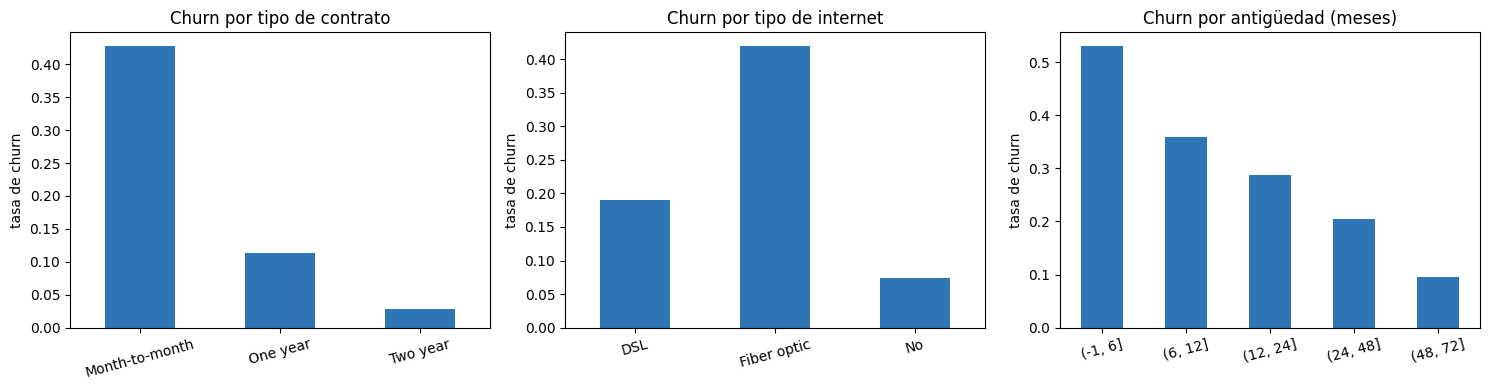

In [8]:
import sys, json, time, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
sys.path.insert(0, "src")
from churn_utils import *
os.makedirs("results", exist_ok=True)

df = cargar_datos("data/processed/telco_churn_clean.csv", "data/processed/split_ids.csv")
feats, cats = columnas_modelo(df)
tr, va, te = [df[df["split"] == s].reset_index(drop=True) for s in ("train", "val", "test")]

print(f"Clientes: {len(df):,} | variables predictoras: {len(feats)} | tasa de churn: {df['Churn'].mean():.2%}")
display(df.groupby("split")["Churn"].agg(clientes="size", tasa_churn="mean").round(4))

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
df.groupby("Contract")["Churn"].mean().plot.bar(ax=ax[0], color="#2E75B6", rot=15); ax[0].set_title("Churn por tipo de contrato")
df.groupby("InternetService")["Churn"].mean().plot.bar(ax=ax[1], color="#2E75B6", rot=15); ax[1].set_title("Churn por tipo de internet")
df.groupby(pd.cut(df["tenure"], [-1, 6, 12, 24, 48, 72]))["Churn"].mean().plot.bar(ax=ax[2], color="#2E75B6", rot=15); ax[2].set_title("Churn por antigüedad (meses)")
for a in ax: a.set_ylabel("tasa de churn"); a.set_xlabel("")
plt.tight_layout(); plt.savefig("results/fig_eda.png", dpi=130); plt.show()

In [9]:
# Hugging Face Datasets: se convierte cada partición a Dataset y se serializa cada cliente a texto
# (los encoders BERT/RoBERTa reciben frases, no columnas).
from datasets import Dataset, DatasetDict
ds = DatasetDict({
    nombre: Dataset.from_pandas(d.assign(text=d.apply(serializar_fila, axis=1))[[ID_COL, "text", "Churn"]], preserve_index=False)
    for nombre, d in (("train", tr), ("validation", va), ("test", te))
})
print(ds)
print("\nEjemplo de cliente serializado:\n", ds["train"][0]["text"])
txt_tr, txt_va, txt_te = (list(ds[s]["text"]) for s in ("train", "validation", "test"))   # listas de Python

DatasetDict({
    train: Dataset({
        features: ['customerID', 'text', 'Churn'],
        num_rows: 4930
    })
    validation: Dataset({
        features: ['customerID', 'text', 'Churn'],
        num_rows: 1056
    })
    test: Dataset({
        features: ['customerID', 'text', 'Churn'],
        num_rows: 1057
    })
})

Ejemplo de cliente serializado:
 Customer with 1 months of tenure. Monthly charges 29.85, total charges 29.85. Contract: Month-to-month. Internet: DSL. Phone service: No. Multiple lines: No phone service. Online security: No. Online backup: Yes. Device protection: No. Tech support: No. Streaming TV: No. Streaming movies: No. Paperless billing: Yes. Payment method: Electronic check. Senior citizen: No. Partner: Yes. Dependents: No.


## 6. Selección de candidatos: criterios y consulta al Hub
Criterios definidos **antes** de los resultados: tipo de tarea, métricas, recursos computacionales, validación con datos propios, licencia y despliegue.

| Criterio | Umbral de aceptación | Origen |
|---|---|---|
| Precisión en el 15 % de mayor riesgo | **≥ 45 %** | Fase I (KPI) |
| ROC-AUC en prueba | **≥ 0.80** | Propuesto: mínimo para discriminar mejor que una regla simple |
| Tiempo para puntuar 400,000 clientes | **≤ 60 min** | Propuesto: la lista es mensual, no en tiempo real |
| Licencia | Compatible con uso comercial interno | Riesgo legal (Fase I) |
| Explicabilidad / costo | Se evalúan cualitativamente en el reporte | Fase I |

In [10]:
CANDIDATOS = {   # nombre -> id en el Hub, tarea de uso, adaptación
    "TabPFN-3":          ("Prior-Labs/tabpfn_3", "Clasificación tabular", "Ninguna (aprendizaje en contexto)"),
    "BERT-mini":         ("google/bert_uncased_L-4_H-256_A-4", "Clasificación de texto (serializado)", "Ajuste fino mínimo"),
    "DistilBERT-base":   ("distilbert-base-uncased", "Clasificación de texto (serializado)", "Ajuste fino mínimo"),
    "RoBERTa-base":      ("roberta-base", "Clasificación de texto (serializado)", "Ajuste fino mínimo"),
}
from huggingface_hub import HfApi
api, filas = HfApi(), []
for nombre, (mid, tarea, adapt) in CANDIDATOS.items():
    fila = {"modelo": nombre, "id_hub": mid, "tarea": tarea, "adaptacion": adapt}
    try:
        info = api.model_info(mid)
        lic = (info.card_data.license if info.card_data and hasattr(info.card_data, "license") else None) or \
              next((t.split(":")[1] for t in (info.tags or []) if t.startswith("license:")), "ver model card")
        fila.update(licencia=lic, descargas_30d=info.downloads, acceso_restringido=bool(info.gated),
                    params_millones=round(info.safetensors.total / 1e6, 1) if getattr(info, "safetensors", None) else None)
    except Exception as e:
        fila.update(licencia=f"no consultada ({type(e).__name__})")
    filas.append(fila)
seleccion = pd.DataFrame(filas)
display(seleccion)
seleccion.to_csv("results/candidatos_hub.csv", index=False)

,modelo,id_hub,tarea,adaptacion,licencia,descargas_30d,acceso_restringido,params_millones
0,TabPFN-3,Prior-Labs/tabpfn_3,Clasificación tabular,Ninguna (aprendizaje en contexto),other,19063,False,NaN
1,BERT-mini,google/bert_uncased_L-4_H-256_A-4,Clasificación de texto (serializado),Ajuste fino mínimo,apache-2.0,98877,False,NaN
2,DistilBERT-base,distilbert-base-uncased,Clasificación de texto (serializado),Ajuste fino mínimo,apache-2.0,7771141,False,67.0
3,RoBERTa-base,roberta-base,Clasificación de texto (serializado),Ajuste fino mínimo,mit,8085334,False,124.7


## 7. Modelos de referencia (no preentrenados)
Se entrenan con las mismas particiones para contestar: *¿qué tanto mejora un modelo preentrenado a algo simple?* Incluye la **regla heurística de la Fase I** (antigüedad + tipo de contrato).

Se define además la función de registro: para cada modelo calcula **accuracy, precision, recall y F1** (clase *Churn*, umbral 0.5), ROC-AUC, PR-AUC, precisión/recall/lift en el 15 % de mayor riesgo, métricas con el umbral que maximiza F1 en validación, **IC 95 % por bootstrap** y **latencia** (lote completo y cliente individual).

In [11]:
RES, ESTADO, HEUR = {}, {}, {}

def registrar(nombre, origen, pv, pt, predict_fn, X_lote, X_unit, n_unit=30, **extra):
    sync = extra.pop("sync", None)
    umbral = mejor_umbral_f1(va["Churn"], pv)
    m = evaluar(te["Churn"], pt, umbral)
    auc_lo, auc_hi = ic_bootstrap(te["Churn"], pt, roc_auc_score)
    p_lo, p_hi = ic_bootstrap(te["Churn"], pt, lambda y, p: precision_recall_topk(y, p)[0])
    lat = medir_latencia(predict_fn, X_lote, X_unit, n_unit=n_unit, sync=sync)
    RES[nombre] = dict(origen=origen, **m, auc_lo=auc_lo, auc_hi=auc_hi, ptop_lo=p_lo, ptop_hi=p_hi, **lat, **extra, _pt=np.asarray(pt))
    ESTADO[nombre] = "ok"

# --- Regla heurística de la Fase I (solo ranking; no tiene probabilidades calibradas)
h = regla_heuristica(te)
pk, rk, lk = precision_recall_topk(te["Churn"], h)
HEUR = {"roc_auc": roc_auc_score(te["Churn"], h), "precision_top15": pk, "recall_top15": rk, "lift_top15": lk}
print("Regla heurística Fase I ->", {k: round(v, 3) for k, v in HEUR.items()})

# --- Modelos clásicos
for nombre, pipe in construir_baselines(feats, cats).items():
    t0 = time.perf_counter(); pipe.fit(tr[feats], tr["Churn"]); t_fit = time.perf_counter() - t0
    pv, pt = pipe.predict_proba(va[feats])[:, 1], pipe.predict_proba(te[feats])[:, 1]
    registrar(nombre, "Referencia (no preentrenado)", pv, pt, lambda X, p=pipe: p.predict_proba(X[feats])[:, 1],
              te, te, t_train=t_fit, params=None)
    r = RES[nombre]
    print(f"{nombre:22s} AUC={r['roc_auc']:.3f} | P@15%={r['precision_top15']:.3f} | F1={r['f1']:.3f} | {r['ms_por_cliente_lote']:.3f} ms/cliente")

Regla heurística Fase I -> {'roc_auc': np.float64(0.786), 'precision_top15': 0.604, 'recall_top15': 0.342, 'lift_top15': 2.271}
Regresión logística    AUC=0.845 | P@15%=0.692 | F1=0.596 | 0.009 ms/cliente
HistGradientBoosting   AUC=0.823 | P@15%=0.673 | F1=0.556 | 0.019 ms/cliente


In [12]:
r = RES.get("Regresión logística")
if r:
    print(f"Conclusión parcial 1 -> La regla heurística de la Fase I logra {HEUR['precision_top15']:.1%} de precisión en el 15 % de mayor riesgo; "
          f"la regresión logística sube a {r['precision_top15']:.1%} (umbral exigido: {UMBRAL_PRECISION_TOPK:.0%}). "
          f"Cualquier modelo preentrenado debe superar esta línea base para justificar su costo.")

Conclusión parcial 1 -> La regla heurística de la Fase I logra 60.4% de precisión en el 15 % de mayor riesgo; la regresión logística sube a 69.2% (umbral exigido: 45%). Cualquier modelo preentrenado debe superar esta línea base para justificar su costo.


## 8. Modelo preentrenado 1 — TabPFN-3 (`Prior-Labs/tabpfn_3`)
Modelo fundacional para datos tabulares entrenado con datos sintéticos.

**No se entrena sobre Telco**: `fit()` solo carga los datos de entrenamiento como *contexto* y la predicción se hace en un paso (aprendizaje en contexto).

Requiere el token de la sección 3 y haber aceptado la licencia; si el acceso falla, el cuaderno **continúa** con los demás modelos y deja registrado el motivo.

In [22]:
from google.colab import userdata
os.environ["TABPFN_TOKEN"] = userdata.get("TABPFN_TOKEN")

In [23]:
try:
    if torch.cuda.is_available(): torch.cuda.reset_peak_memory_stats()
    pred_tabpfn, info_t = correr_tabpfn(tr, tr["Churn"], feats, cats)
    pv, pt = pred_tabpfn(va), pred_tabpfn(te)
    gpu = torch.cuda.max_memory_allocated() / 2**20 if torch.cuda.is_available() else None
    registrar("TabPFN-3", "Preentrenado HF (tabular, sin entrenamiento)", pv, pt, pred_tabpfn, te, te, n_unit=10,
              t_train=info_t["t_fit"], params=info_t["params"], gpu_mem_mb=gpu,
              sync=(torch.cuda.synchronize if torch.cuda.is_available() else None))
    r = RES["TabPFN-3"]
    print(f"TabPFN-3 AUC={r['roc_auc']:.3f} | P@15%={r['precision_top15']:.3f} | F1={r['f1']:.3f} | {r['ms_por_cliente_lote']:.2f} ms/cliente (lote)")
except Exception as e:
    ESTADO["TabPFN-3"] = f"No ejecutado: {type(e).__name__}: {str(e)[:300]}"
    print(ESTADO["TabPFN-3"])
    print("Pista: confirma que aceptaste la licencia en https://huggingface.co/Prior-Labs/tabpfn_3 y que HF_TOKEN está activo "
          "(si el mensaje pide un token de Prior Labs, defínelo como Secret TABPFN_TOKEN). El resto del cuaderno continúa sin este modelo.")

tabpfn-v3.5-20260909.safetensors: reconstructing file:   0%|          |  0.00B /  876MB            

tabpfn-v3.5-20260909.safetensors: downloading bytes:           |  0.00B            

config.json:   0%|          | 0.00/36.0 [00:00<?, ?B/s]

TabPFN-3 AUC=0.850 | P@15%=0.711 | F1=0.564 | 5.25 ms/cliente (lote)


## 9. Modelos preentrenados 2–4 — encoders de texto de Hugging Face
Cada cliente se serializa a una frase y se ajusta un encoder preentrenado con un **ajuste fino mínimo**: 3–6 épocas, tasa de aprendizaje pequeña, bucle PyTorch simple, se conserva la época con mejor AUC en **validación** (no en prueba). Los tres modelos cubren un rango de tamaño: 11 M, 66 M y 125 M de parámetros.

> Estos modelos se diseñaron para lenguaje, no para tablas. Se incluyen a propósito para comprobar si la opción *popular* (transformers) supera a la opción *especializada*, justo el sesgo de elegir por popularidad que advierte el Tema 9.

In [24]:
ENCODERS = [
    ("BERT-mini",       "google/bert_uncased_L-4_H-256_A-4", dict(epochs=6, lr=1e-4)),
    ("DistilBERT-base", "distilbert-base-uncased",           dict(epochs=3, lr=3e-5)),
    ("RoBERTa-base",    "roberta-base",                      dict(epochs=3, lr=2e-5)),
]
HIST, DEMO = {}, None
import gc
for nombre, mid, hp in ENCODERS:
    try:
        print(f"\n=== {nombre} ({mid}) ===")
        pred, info_e = entrenar_encoder_texto(mid, txt_tr, tr["Churn"].values, txt_va, va["Churn"].values, **hp)
        pv, pt = pred(txt_va), pred(txt_te)
        registrar(nombre, "Preentrenado HF (texto, ajuste fino mínimo)", pv, pt, pred, txt_te, txt_te, n_unit=30,
                  t_train=info_e["t_train"], params=info_e["params"], gpu_mem_mb=info_e["gpu_mem_mb"], sync=info_e["sync"])
        HIST[nombre] = info_e["hist"]
        r = RES[nombre]
        print(f"{nombre} AUC={r['roc_auc']:.3f} | P@15%={r['precision_top15']:.3f} | F1={r['f1']:.3f} | entrenamiento {r['t_train']:.0f} s")
        if mid == "distilbert-base-uncased":
            DEMO = (info_e["model"], info_e["tok"])
    except Exception as e:
        ESTADO[nombre] = f"No ejecutado: {type(e).__name__}: {str(e)[:300]}"
        print(ESTADO[nombre])
    finally:
        info_e = None; pred = None; gc.collect()
        if torch.cuda.is_available(): torch.cuda.empty_cache()


=== BERT-mini (google/bert_uncased_L-4_H-256_A-4) ===


config.json:   0%|          | 0.00/383 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 45.1MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

...

model.safetensors: reconstructing file:   0%|          |  0.00B /  499MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: roberta-base
Key                        | Status     | 
---------------------------+------------+-
lm_head.layer_norm.bias    | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
lm_head.bias               | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
classifier.out_proj.weight | MISSING    | 
classifier.dense.weight    | MISSING    | 
classifier.dense.bias      | MISSING    | 
classifier.out_proj.bias   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


  [roberta-base] epoch 1/3 loss=0.5194 AUC val=0.8064
  [roberta-base] epoch 2/3 loss=0.4535 AUC val=0.8395
  [roberta-base] epoch 3/3 loss=0.4340 AUC val=0.8427
RoBERTa-base AUC=0.831 | P@15%=0.660 | F1=0.522 | entrenamiento 101 s


In [25]:
# Pipeline de inferencia de Hugging Face con el modelo ajustado (3 clientes de prueba)
if DEMO is not None:
    from transformers import pipeline
    clf = pipeline("text-classification", model=DEMO[0], tokenizer=DEMO[1],
                   device=0 if torch.cuda.is_available() else -1, top_k=None)
    for i in range(3):
        sal = clf(txt_te[i], truncation=True, max_length=192)[0]
        p_churn = [s["score"] for s in sal if s["label"] in ("LABEL_1", "1")][0]
        print(f"Cliente {te.loc[i, ID_COL]} | churn real = {te.loc[i, 'Churn']} | prob. de churn = {p_churn:.2f}")
else:
    print("DistilBERT no se ejecutó; no hay modelo para la demostración del pipeline.")

Cliente 7795-CFOCW | churn real = 0 | prob. de churn = 0.06
Cliente 1452-KIOVK | churn real = 0 | prob. de churn = 0.36
Cliente 6713-OKOMC | churn real = 0 | prob. de churn = 0.21


In [26]:
# Conclusión parcial 2: relación tamaño / desempeño de los encoders
hf = [n for n in ("BERT-mini", "DistilBERT-base", "RoBERTa-base") if n in RES]
if hf:
    mejor = max(hf, key=lambda n: RES[n]["roc_auc"])
    print("Conclusión parcial 2 -> AUC por tamaño:", {n: round(RES[n]["roc_auc"], 3) for n in hf})
    print(f"El mejor encoder de texto es {mejor} (AUC {RES[mejor]['roc_auc']:.3f}, IC95% [{RES[mejor]['auc_lo']:.3f}, {RES[mejor]['auc_hi']:.3f}]).")
    if "Regresión logística" in RES:
        d = RES[mejor]["roc_auc"] - RES["Regresión logística"]["roc_auc"]
        print(f"Frente a la regresión logística la diferencia de AUC es {d:+.3f}; un modelo {RES[mejor]['params']/1e6:.0f} M de parámetros "
              f"necesita {RES[mejor]['ms_por_cliente_lote']/max(RES['Regresión logística']['ms_por_cliente_lote'],1e-9):.0f}x más tiempo por cliente.")

Conclusión parcial 2 -> AUC por tamaño: {'BERT-mini': np.float64(0.834), 'DistilBERT-base': np.float64(0.84), 'RoBERTa-base': np.float64(0.831)}
El mejor encoder de texto es DistilBERT-base (AUC 0.840, IC95% [0.811, 0.864]).
Frente a la regresión logística la diferencia de AUC es -0.006; un modelo 67 M de parámetros necesita 321x más tiempo por cliente.


## 10. Consolidación de resultados
Tabla comparativa con las métricas exigidas (accuracy, precision, recall, F1), ranking, top-15 %, latencia y recursos.

In [27]:
def v(r, k): return r.get(k)
orden = list(RES.keys())
tabla = pd.DataFrame({n: {k: v(RES[n], k) for k in RES[n] if not k.startswith("_")} for n in orden}).T
tabla.index.name = "modelo"
cols_met = ["origen", "accuracy", "precision", "recall", "f1", "roc_auc", "pr_auc", "precision_top15", "recall_top15", "lift_top15"]
cols_ump = ["umbral_val", "precision_umbral_val", "recall_umbral_val", "f1_umbral_val"]
cols_lat = ["ms_por_cliente_lote", "ms_unitario_mediana", "ms_unitario_p95", "min_estimados_400k", "t_train", "params", "gpu_mem_mb"]
print("Métricas de desempeño (prueba, clase Churn; umbral 0.5 salvo donde se indica)")
display(tabla.reindex(columns=cols_met).round(3))
print("Con el umbral que maximiza F1 en validación")
display(tabla.reindex(columns=cols_ump).astype(float).round(3))
print("Latencia y recursos")
display(tabla.reindex(columns=cols_lat).astype(float).round(3))
print("Intervalos de confianza 95 % (bootstrap, 1,000 remuestreos)")
display(tabla[["auc_lo", "roc_auc", "auc_hi", "ptop_lo", "precision_top15", "ptop_hi"]].astype(float).round(3))
if ESTADO and any(s != "ok" for s in ESTADO.values()):
    print("Modelos no ejecutados:", {k: s for k, s in ESTADO.items() if s != "ok"})

tabla.to_csv("results/metricas_comparativas.csv")
pred_df = te[[ID_COL, "Churn"]].copy()
for n in orden: pred_df["p_" + n] = RES[n]["_pt"]
pred_df.to_csv("results/predicciones_test.csv", index=False)

Métricas de desempeño (prueba, clase Churn; umbral 0.5 salvo donde se indica)


,origen,accuracy,precision,recall,f1,roc_auc,pr_auc,precision_top15,recall_top15,lift_top15
modelo,,,,,,,,,,
Regresión logística,Referencia (no preentrenado),0.809839,0.685185,0.52669,0.595573,0.845209,0.65813,0.691824,0.391459,2.602341
HistGradientBoosting,Referencia (no preentrenado),0.789972,0.634703,0.494662,0.556,0.82305,0.634089,0.672956,0.380783,2.531368
TabPFN-3,"Preentrenado HF (tabular, sin entrenamiento)",0.802271,0.681818,0.480427,0.563674,0.84985,0.685681,0.710692,0.402135,2.673314
BERT-mini,"Preentrenado HF (texto, ajuste fino mínimo)",0.790918,0.664835,0.430605,0.522678,0.833754,0.647442,0.679245,0.384342,2.555026
DistilBERT-base,"Preentrenado HF (texto, ajuste fino mínimo)",0.798486,0.671717,0.47331,0.555324,0.839518,0.660903,0.716981,0.405694,2.696972
RoBERTa-base,"Preentrenado HF (texto, ajuste fino mínimo)",0.789972,0.661202,0.430605,0.521552,0.830697,0.636956,0.660377,0.373665,2.484053


Con el umbral que maximiza F1 en validación


,umbral_val,precision_umbral_val,recall_umbral_val,f1_umbral_val
modelo,,,,
Regresión logística,0.259,0.510,0.786,0.619
HistGradientBoosting,0.323,0.542,0.665,0.597
TabPFN-3,0.310,0.551,0.744,0.633
BERT-mini,0.190,0.525,0.747,0.617
DistilBERT-base,0.238,0.508,0.776,0.614
RoBERTa-base,0.288,0.517,0.740,0.609


Latencia y recursos


,ms_por_cliente_lote,ms_unitario_mediana,ms_unitario_p95,min_estimados_400k,t_train,params,gpu_mem_mb
modelo,,,,,,,
Regresión logística,0.009,6.063,9.640,0.059,0.200,NaN,NaN
HistGradientBoosting,0.019,6.261,8.201,0.125,0.453,NaN,NaN
TabPFN-3,5.245,4668.149,4831.021,34.968,15.064,218982656.0,3928.503
BERT-mini,0.532,5.707,6.989,3.549,49.533,11171074.0,1166.584
DistilBERT-base,2.820,51.610,69.003,18.801,53.883,66955010.0,2462.998
RoBERTa-base,1.728,13.296,16.201,11.522,100.786,124647170.0,4455.004


Intervalos de confianza 95 % (bootstrap, 1,000 remuestreos)


,auc_lo,roc_auc,auc_hi,ptop_lo,precision_top15,ptop_hi
modelo,,,,,,
Regresión logística,0.819,0.845,0.868,0.623,0.692,0.774
HistGradientBoosting,0.794,0.823,0.849,0.597,0.673,0.742
TabPFN-3,0.823,0.850,0.872,0.641,0.711,0.792
BERT-mini,0.806,0.834,0.859,0.610,0.679,0.755
DistilBERT-base,0.811,0.840,0.864,0.642,0.717,0.786
RoBERTa-base,0.803,0.831,0.855,0.591,0.660,0.742


## 11. Visualizaciones

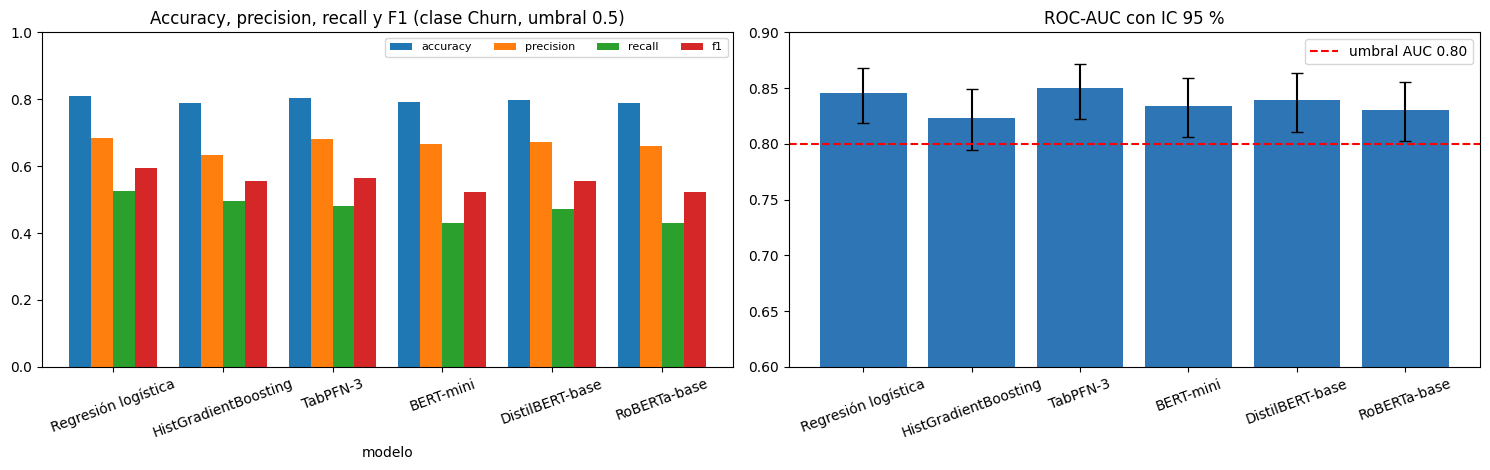

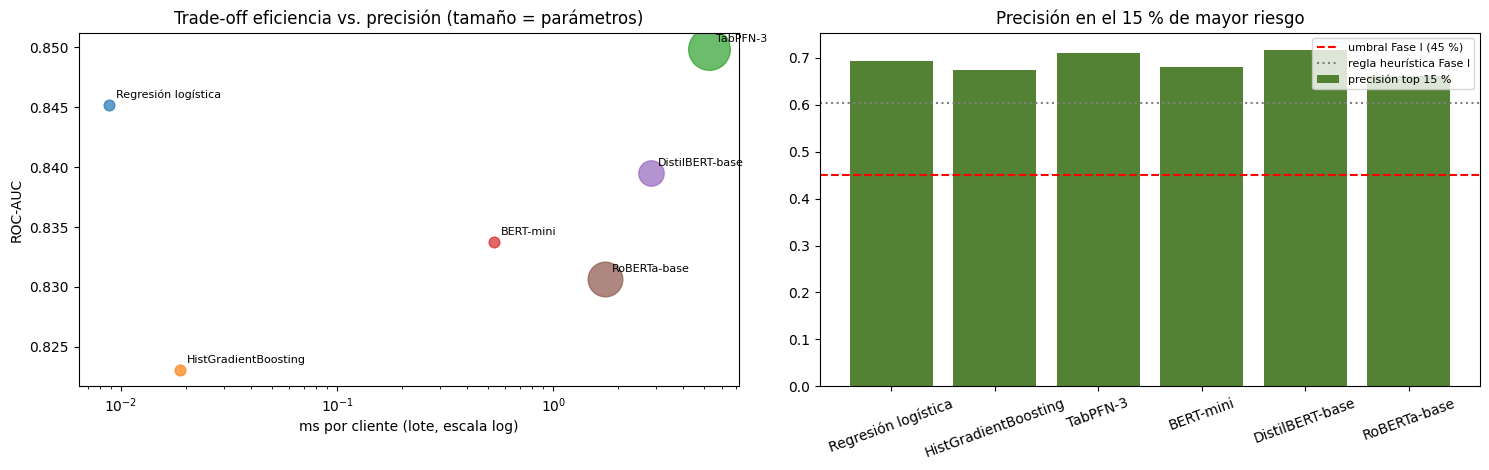

In [28]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4.8))
m4 = tabla[["accuracy", "precision", "recall", "f1"]].astype(float)
m4.plot.bar(ax=ax[0], rot=20, width=0.8); ax[0].set_title("Accuracy, precision, recall y F1 (clase Churn, umbral 0.5)"); ax[0].set_ylim(0, 1); ax[0].legend(ncol=4, fontsize=8)
t = tabla.drop(columns=["origen"]).astype(float)
err = np.array([t["roc_auc"] - t["auc_lo"], t["auc_hi"] - t["roc_auc"]]).astype(float)
ax[1].bar(t.index, t["roc_auc"].astype(float), yerr=err, capsize=4, color="#2E75B6"); ax[1].set_ylim(0.6, 0.9)
ax[1].axhline(0.80, color="red", ls="--", label="umbral AUC 0.80"); ax[1].set_title("ROC-AUC con IC 95 %"); ax[1].legend(); ax[1].tick_params(axis="x", rotation=20)
plt.tight_layout(); plt.savefig("results/fig_metricas.png", dpi=130); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(15, 4.8))
for n in t.index:
    pr = RES[n]["params"] or 1e6
    ax[0].scatter(t.loc[n, "ms_por_cliente_lote"], t.loc[n, "roc_auc"], s=max(60, min(900, pr / 2e5)), alpha=0.7)
    ax[0].annotate(n, (t.loc[n, "ms_por_cliente_lote"], t.loc[n, "roc_auc"]), fontsize=8, xytext=(5, 5), textcoords="offset points")
ax[0].set_xscale("log"); ax[0].set_xlabel("ms por cliente (lote, escala log)"); ax[0].set_ylabel("ROC-AUC"); ax[0].set_title("Trade-off eficiencia vs. precisión (tamaño = parámetros)")
ax[1].bar(t.index, t["precision_top15"].astype(float), color="#548235", label="precisión top 15 %")
ax[1].axhline(UMBRAL_PRECISION_TOPK, color="red", ls="--", label="umbral Fase I (45 %)")
ax[1].axhline(HEUR["precision_top15"], color="gray", ls=":", label="regla heurística Fase I")
ax[1].set_title("Precisión en el 15 % de mayor riesgo"); ax[1].legend(fontsize=8); ax[1].tick_params(axis="x", rotation=20)
plt.tight_layout(); plt.savefig("results/fig_tradeoff.png", dpi=130); plt.show()

## 12. Decisión: umbrales, trade-offs y modelo recomendado
**Regla de decisión (definida antes de ver resultados):**
1. Pasan el filtro los modelos con precisión top 15 % ≥ 45 %, AUC ≥ 0.80 y ≤ 60 min para puntuar 400,000 clientes.
2. Entre los que pasan, se consideran **equivalentes** los que están a menos de 0.01 de AUC del mejor (diferencia menor al error de muestreo del IC 95 %).
3. Entre los equivalentes se elige el de **menor costo de operación** (tiempo de puntuación, luego parámetros).
Se reportan dos resultados: el mejor **modelo preentrenado de Hugging Face** y el mejor **global** (incluyendo referencias).

In [29]:
UMBRALES = dict(precision_top15=UMBRAL_PRECISION_TOPK, roc_auc=0.80, min_estimados_400k=60.0)
def cumple(r): return (r["precision_top15"] >= UMBRALES["precision_top15"] and r["roc_auc"] >= UMBRALES["roc_auc"]
                       and r["min_estimados_400k"] <= UMBRALES["min_estimados_400k"])
def elegir(nombres):
    ok = [n for n in nombres if cumple(RES[n])]
    if not ok: return None, []
    mejor_auc = max(RES[n]["roc_auc"] for n in ok)
    eq = [n for n in ok if mejor_auc - RES[n]["roc_auc"] < 0.01]
    return min(eq, key=lambda n: (RES[n]["min_estimados_400k"], RES[n]["params"] or 0)), eq

hf_modelos = [n for n in RES if RES[n]["origen"].startswith("Preentrenado")]
rec_hf, eq_hf = elegir(hf_modelos)
rec_global, eq_global = elegir(list(RES))
cumplimiento = pd.DataFrame({n: {"precision_top15 >= 45%": RES[n]["precision_top15"] >= 0.45, "AUC >= 0.80": RES[n]["roc_auc"] >= 0.80,
                                 "400k clientes <= 60 min": RES[n]["min_estimados_400k"] <= 60} for n in RES}).T
display(cumplimiento)
print("Mejor modelo preentrenado de Hugging Face:", rec_hf, "| equivalentes en AUC:", eq_hf)
print("Mejor modelo global (incluye referencias):", rec_global, "| equivalentes en AUC:", eq_global)
json.dump({"umbrales": UMBRALES, "recomendado_hf": rec_hf, "equivalentes_hf": eq_hf, "recomendado_global": rec_global,
           "equivalentes_global": eq_global, "estado": ESTADO, "heuristica_fase1": HEUR}, open("results/decision.json", "w"), indent=2, default=float)

,precision_top15 >= 45%,AUC >= 0.80,400k clientes <= 60 min
Regresión logística,True,True,True
HistGradientBoosting,True,True,True
TabPFN-3,True,True,True
BERT-mini,True,True,True
DistilBERT-base,True,True,True
RoBERTa-base,True,True,True


Mejor modelo preentrenado de Hugging Face: TabPFN-3 | equivalentes en AUC: ['TabPFN-3']
Mejor modelo global (incluye referencias): Regresión logística | equivalentes en AUC: ['Regresión logística', 'TabPFN-3']


## 14. Conclusiones parciales

In [31]:
print("CONCLUSIONES AUTOMÁTICAS (basadas en los resultados de esta ejecución)")
if rec_hf: print(f"- Mejor modelo preentrenado HF bajo la regla de decisión: {rec_hf} (AUC {RES[rec_hf]['roc_auc']:.3f}, P@15% {RES[rec_hf]['precision_top15']:.1%}, {RES[rec_hf]['min_estimados_400k']:.1f} min para 400,000 clientes).")
if rec_global and rec_global != rec_hf: print(f"- Ojo: el mejor modelo global es {rec_global}, un modelo de referencia; la complejidad del preentrenado no se justifica solo por precisión.")
if RES: print(f"- Todos los modelos listados {'superan' if all(RES[n]['precision_top15'] >= 0.45 for n in RES) else 'NO superan en su totalidad'} el 45 % de precisión de la Fase I en el top 15 %.")
print("- Recuerda: en este dataset de muestra la tasa de churn es 26.5 % (clientes que se fueron en el último mes, según su data card) frente al 22 % anual supuesto en la Fase I. La comparación entre modelos es válida, pero el ROI debe recalcularse con datos propios de la operadora.")

# Registro del entorno para reproducibilidad
import platform, importlib
entorno = {"python": platform.python_version(), "semilla": SEED, "gpu": (torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")}
for lib in ["numpy", "pandas", "sklearn", "torch", "transformers", "datasets", "huggingface_hub", "tabpfn"]:
    try: entorno[lib] = importlib.import_module(lib).__version__
    except Exception: entorno[lib] = "no instalada"
json.dump(entorno, open("results/entorno.json", "w"), indent=2); print(entorno)
pd.DataFrame([{"modelo": k, "estado": s} for k, s in ESTADO.items()]).to_csv("results/estado_modelos.csv", index=False)
for n, h_ in HIST.items(): pd.DataFrame(h_).assign(modelo=n).to_csv(f"results/historial_{n}.csv", index=False)

CONCLUSIONES AUTOMÁTICAS (basadas en los resultados de esta ejecución)
- Mejor modelo preentrenado HF bajo la regla de decisión: TabPFN-3 (AUC 0.850, P@15% 71.1%, 35.0 min para 400,000 clientes).
- Ojo: el mejor modelo global es Regresión logística, un modelo de referencia; la complejidad del preentrenado no se justifica solo por precisión.
- Todos los modelos listados superan el 45 % de precisión de la Fase I en el top 15 %.
- Recuerda: en este dataset de muestra la tasa de churn es 26.5 % (clientes que se fueron en el último mes, según su data card) frente al 22 % anual supuesto en la Fase I. La comparación entre modelos es válida, pero el ROI debe recalcularse con datos propios de la operadora.
{'python': '3.13.15', 'semilla': 42, 'gpu': 'Tesla T4', 'numpy': '2.1.3', 'pandas': '2.2.3', 'sklearn': '1.6.1', 'torch': '2.11.0+cu130', 'transformers': '5.18.0', 'datasets': '4.8.5', 'huggingface_hub': '1.33.0', 'tabpfn': '9.1.0'}
